/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/tmp/ipykernel_4898/3060495141.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


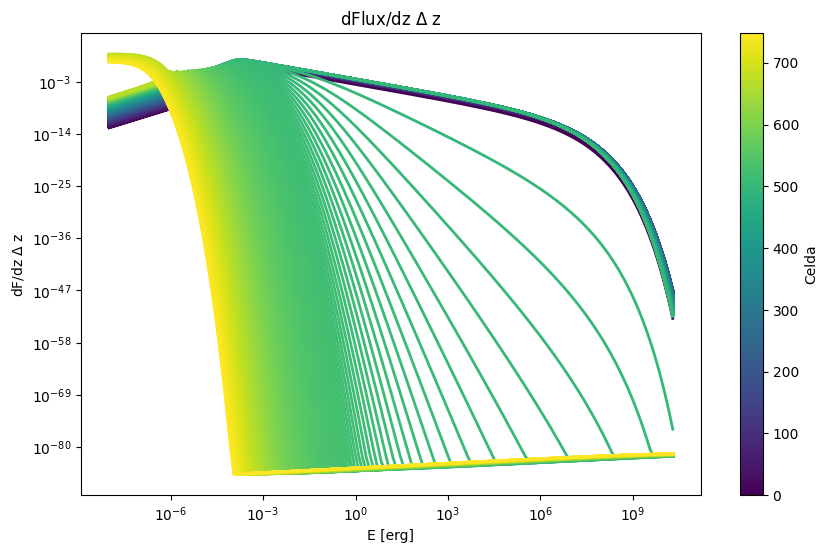

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Cargar los datos
data = np.loadtxt('./../Code/dFlux_dz.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = y_values.shape[1]

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(x, y_values[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_ylim(1e-62,1e-60)
ax.set_xlabel(r'E [erg]')  # Ajustar según los datos
ax.set_ylabel(r'dF/dz $\Delta$ z')  # Ajustar según los datos
ax.set_title(r'dFlux/dz $\Delta$ z')

plt.show()

In [48]:
import pandas as pd

# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer columnas
E = data[:, 0]  # Primer columna
N = data[:, 1]  # Segunda columna
Z = data[:, 2]  # Tercera columna

data2 = np.loadtxt('./../Code/quant_FF.dat')
# Encontrar valores únicos de E y Z
r=data2[:, 2]
Deltaz=data2[:, -2]

E_unique = np.unique(E)
Z_unique = np.unique(Z)

# Crear una matriz de N con dimensiones (len(E_unique), len(Z_unique))
N_matrix = np.full((len(E_unique), len(Z_unique)), np.nan)  # Usamos NaN para identificar valores faltantes

# Rellenar la matriz
for e, n, z in zip(E, N, Z):
    i = np.where(E_unique == e)[0][0]
    j = np.where(Z_unique == z)[0][0]
    N_matrix[i, j] = n

N_matrix
# Convert the matrix to a DataFrame
df = pd.DataFrame(N_matrix, index=E_unique, columns=Z_unique)

print(E_unique[1])
Deltaz[:]

1.8612468694701466e-06


array([2.99884818e+11, 3.05471369e+11, 3.11161993e+11, 3.16958626e+11,
       3.22863245e+11, 3.28877862e+11, 3.35004524e+11, 3.41245320e+11,
       3.47602376e+11, 3.54077857e+11, 3.60673970e+11, 3.67392962e+11,
       3.74237122e+11, 3.81208782e+11, 3.88310316e+11, 3.95544145e+11,
       4.02912733e+11, 4.10418591e+11, 4.18064275e+11, 4.25852390e+11,
       4.33785590e+11, 4.41866578e+11, 4.50098106e+11, 4.58482979e+11,
       4.67024054e+11, 4.75724240e+11, 4.84586503e+11, 4.93613860e+11,
       5.02809388e+11, 5.12176219e+11, 5.21717545e+11, 5.31436616e+11,
       5.41336743e+11, 5.51421300e+11, 5.61693722e+11, 5.72157509e+11,
       5.82816226e+11, 5.93673503e+11, 6.04733041e+11, 6.15998607e+11,
       6.27474039e+11, 6.39163247e+11, 6.51070213e+11, 6.63198994e+11,
       6.75553721e+11, 6.88138605e+11, 7.00957932e+11, 7.14016071e+11,
       7.27317469e+11, 7.40866659e+11, 7.54668257e+11, 7.68726964e+11,
       7.83047572e+11, 7.97634957e+11, 8.12494091e+11, 8.27630035e+11,
      

/tmp/ipykernel_4898/1449568818.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


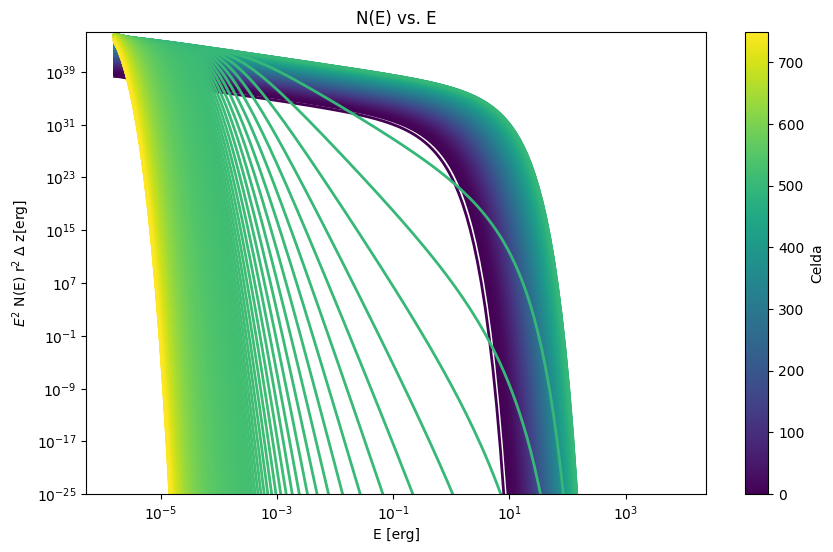

In [47]:
# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = len(Z_unique)

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(E_unique, E_unique**2*df.iloc[:, i]*r[i]**2*Deltaz[i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-25,1e45)
ax.set_xlabel(r'E [erg]')  # Ajustar según los datos
ax.set_ylabel(r'$E^2$ N(E) r$^2$ $\Delta$ z[erg]')  # Ajustar según los datos
ax.set_title(r'N(E) vs. E')

plt.show()